# Teks — Analisis Kesalahan Prediksi + Penanda Otomatis dengan Laya
**Kapan dipakai:** SETELAH model jadi, untuk mencari pola kesalahan (bahan perbaikan dan
presentasi).

**Langkah:**
1. Prediksi OOF 5-fold → semua teks train punya prediksi "jujur".
2. Kesalahan dikelompokkan per kelas tertukar, panjang teks, kata negasi/kontras.
3. Tanda dari Laya (model keputusan zero-shot): sarkas? campur pujian-keluhan? topik apa?

Tanda Laya tidak selalu benar (lihat README-nya), jadi dipakai untuk MENCARI POLA, bukan
sebagai feature pasti. Selalu baca beberapa contoh sebelum menyimpulkan.

**Data demo:** SmSA (sentimen). Model: TF-IDF + LogisticRegression.

In [1]:
import laya
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

## Konfigurasi
`QUESTIONS`: pertanyaan untuk Laya, ditulis bebas. Tipe `choice` dengan kunci netral (A/B)
lebih stabil daripada `noul` (ya/tidak) menurut README Laya.

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/text/sentiment"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/smsa_train.csv"
LAYA_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/laya"

TEXT_COL = "text"
TARGET = "label"
N_FLAGGED = 300      # jumlah teks salah dan benar yang diberi tanda Laya (±0.2 detik per teks)
SEED = 42
QUESTIONS = {
    "sarkas": {"type": "choice", "instructions": "Apakah teks ini sindiran atau sarkasme?",
               "criteria": {"A": "ya, menyindir", "B": "tidak, makna apa adanya"}},
    "campur": {"type": "choice", "instructions": "Apakah teks memuji dan mengeluh sekaligus?",
               "criteria": {"A": "ya, ada pujian dan keluhan", "B": "tidak, satu nada saja"}},
    "topik": {"type": "choice", "instructions": "Teks ini membahas apa?",
              "criteria": {"makanan": "restoran, makanan, minuman", "politik": "politik, tokoh",
                           "layanan": "hotel, toko, aplikasi, pelayanan", "lain": "lainnya"}},
}

## Baca data

In [3]:
data = pd.read_csv(DATA_CSV)
data[TEXT_COL] = data[TEXT_COL].fillna("")
print(data.shape)
print(data[TARGET].value_counts())
data.head()

(5148, 3)
label
negative    2000
positive    2000
neutral     1148
Name: count, dtype: int64


,id,text,label
0,1,kenapa lumayan enak ? karena ada sushi lain ya...,negative
1,2,berarti staff nya anies yang tidak becus mengu...,negative
2,3,orang cina makanan legendaris sudah lama bange...,negative
3,4,"mental apa ini pak jokowi , bagaimana ini pak ...",negative
4,5,selama iblis binatang ini jadi kapolri jangan ...,negative


## Model + prediksi OOF 5-fold
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [4]:
model = LogisticRegression(C=3.0, max_iter=2000)
# model = LinearSVC(C=0.5)

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
pipe = make_pipeline(vectorizer, model)
folds = StratifiedKFold(5, shuffle=True, random_state=SEED)
data["prediksi"] = cross_val_predict(pipe, data[TEXT_COL], data[TARGET], cv=folds)
data["salah"] = data["prediksi"] != data[TARGET]
print("persen salah:", round(data["salah"].mean(), 4))

persen salah: 0.1408


## 1. Kelas mana yang tertukar?

              precision    recall  f1-score   support

    negative      0.838     0.861     0.849      2000
     neutral      0.866     0.814     0.839      1148
    positive      0.878     0.883     0.880      2000

    accuracy                          0.859      5148
   macro avg      0.860     0.853     0.856      5148
weighted avg      0.859     0.859     0.859      5148



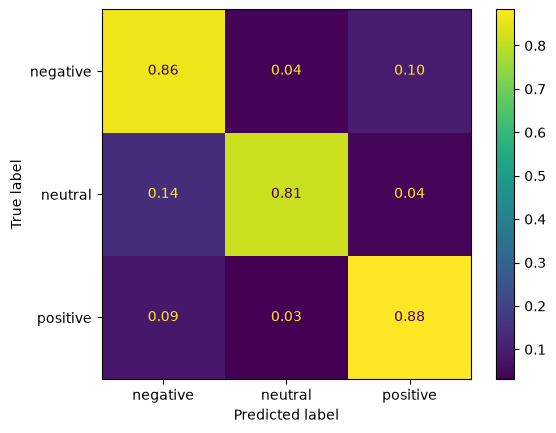

In [5]:
print(classification_report(data[TARGET], data["prediksi"], digits=3))
ConfusionMatrixDisplay.from_predictions(data[TARGET], data["prediksi"], normalize="true",
                                        values_format=".2f")
plt.show()

## 2. Ciri sederhana: panjang teks, kata negasi, kata kontras
Persen salah per kelompok. Kelompok yang persen salahnya jauh lebih tinggi = titik lemah model.

In [6]:
data["jumlah_kata"] = data[TEXT_COL].str.split().str.len()
data["ada_negasi"] = data[TEXT_COL].str.contains(r"\b(?:tidak|bukan|gak|nggak|tak|belum)\b")
data["ada_kontras"] = data[TEXT_COL].str.contains(r"\b(?:tapi|tetapi|namun|walaupun|meski)\b")

length_group = pd.qcut(data["jumlah_kata"], 4)
error_by_length = data.groupby(length_group, observed=True)["salah"].mean()
print(error_by_length.round(3), "\n")
for col in ["ada_negasi", "ada_kontras"]:
    error_by_flag = data.groupby(col)["salah"].agg(["mean", "size"])
    print(error_by_flag.round(3), "\n")

jumlah_kata
(0.999, 12.0]    0.176
(12.0, 23.0]     0.133
(23.0, 41.0]     0.114
(41.0, 97.0]     0.135
Name: salah, dtype: float64 

             mean  size
ada_negasi             
False       0.129  3366
True        0.163  1782 

              mean  size
ada_kontras             
False        0.135  4309
True         0.169   839 



## 3. Tanda dari Laya untuk sampel teks salah dan benar

In [7]:
agent = laya.load(LAYA_FOLDER, subfolder="multilingual")
wrong_sample = data[data["salah"]].sample(N_FLAGGED, random_state=SEED)
right_sample = data[~data["salah"]].sample(N_FLAGGED, random_state=SEED)
sample = pd.concat([wrong_sample, right_sample])

for name in QUESTIONS:
    sample[name] = ""
for row_index, text in zip(sample.index, sample[TEXT_COL]):
    answers = agent.predict(text, QUESTIONS)["answers"]
    for name in QUESTIONS:
        sample.loc[row_index, name] = answers[name]["choice"]
sample[list(QUESTIONS)].describe()

,sarkas,campur,topik
count,600,600,600
unique,2,2,4
top,B,B,makanan
freq,528,541,221


## 4. Tanda mana yang lebih sering salah?
Persen salah di sampel = 50% bila tanda tidak berhubungan dengan kesalahan.

In [8]:
for name in QUESTIONS:
    error_by_answer = sample.groupby(name)["salah"].agg(["mean", "size"])
    print(error_by_answer.round(3), "\n")

         mean  size
sarkas             
A       0.417    72
B       0.511   528 

         mean  size
campur             
A       0.356    59
B       0.516   541 

          mean  size
topik               
lain     0.588   160
layanan  0.632    68
makanan  0.502   221
politik  0.344   151 



## 5. Baca contoh (wajib sebelum menyimpulkan)
Contoh: teks yang salah DAN ditandai "campur" oleh Laya.

In [9]:
pd.set_option("display.max_colwidth", 150)
mixed_wrong = sample[sample["salah"] & (sample["campur"] == "A")]
mixed_wrong[[TEXT_COL, TARGET, "prediksi"]].head(8)

,text,label,prediksi
3746,"jokowo tidak pernah gagal dalam menurunkan harga bbm , sungguh prestasi yang membanggakan",positive,negative
490,"datang terus hujan , lalu makan iga bakar rasa iga kuah asem manis . minta lilin karena banyak lalat dikasih lilin pakai tissue yang api nya jadi ...",negative,positive
559,"tempat bagus nyaman pelayanan nya ramah untuk kamar mandi jauh dari layak , untuk cuci tangan tidak disediakan sabun .",negative,positive
4895,"betuuuul , aku pakai jakarta inspired lipcream cantik sekali dan longlasting , masih worth untuk harga di bawah 100k .",positive,negative
3349,"bagaimana pun netijen menghina prabowo , beliau tidak akan dendam atau membalas dengan perlakuan yang sama . itulah kenapa saya sangat mengagumi b...",positive,negative
238,restoran ala kamu bisa makan ini sudah bertahan cukup lama . di sini yang menjadi favorit saya adalah thai thea dan daging nya yang enak . siap-si...,negative,positive
239,"saya pernah ke lokasi yang di progo , memesan pizza dan kurang empuk untuk bagian roti nya , pokok nya kurang , deh . tapi kalau minuman nya , sih...",negative,positive
554,"tizi s merupakan salah satu restoran langganan keluarga saya . tapi sudah lama saya sendiri tidak pernah makan di sini . dulu sekali , ketika saya...",negative,positive


## Simpan tabel kesalahan (bahan laporan / cek manual)
Langkah lanjut umum: tambah n-gram negasi ("tidak_enak"), model kontekstual (IndoBERT) untuk
teks campur/sarkas, periksa ulang label teks yang salah dengan nada jelas.

In [10]:
error_table = pd.DataFrame()
error_table["id"] = data["id"]
error_table["label"] = data[TARGET]
error_table["prediksi"] = data["prediksi"]
error_table["salah"] = data["salah"]
error_table["jumlah_kata"] = data["jumlah_kata"]
error_table.to_csv("analisis_kesalahan.csv", index=False)
sample.drop(columns=[TEXT_COL]).to_csv("tanda_laya.csv", index=False)
error_table[error_table["salah"]].head()

,id,label,prediksi,salah,jumlah_kata
0,1,negative,positive,True,76
5,6,negative,positive,True,71
6,7,negative,positive,True,25
7,8,negative,neutral,True,11
14,15,negative,neutral,True,20
